# فاز دوم - تسک ۳: خوشه‌بندی جملات و کشف جنبه‌های محصول (Aspect Discovery)
**مسیر ب (Amazon Reviews'23 - Toys & Games)**

در این نوت‌بوک مطابق با الزامات فاز دوم شیوه‌نامه:
1. داده‌های متنی و امبدینگ‌های کش‌شده از دوره آموزش (2015-2020) بارگذاری می‌شوند.
2. تعداد بهینه خوشه‌ها (k) با معیارهای کمی Silhouette Score و Elbow ارزیابی و انتخاب می‌شود.
3. با تلفیق ماتریس TF-IDF، کلمات کلیدی متمایز هر خوشه استخراج و تفسیر می‌شوند.
4. ارتباط خوشه‌ها با امتیاز کاربران (Rating) بررسی و نقشه رنگی خوشه‌ها در فضای UMAP ذخیره می‌گردد.



In [1]:
import os
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import umap

# تنظیمات نمایش فارسی در نمودارها و مسیر ریشه پروژه
plt.rcParams["axes.unicode_minus"] = False

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

interim_dir = project_root / "data" / "interim"
figures_dir = project_root / "figures" / "phase2"
models_dir = project_root / "models" / "phase2"

figures_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

print(f"مسیر ریشه پروژه: {project_root}")



مسیر ریشه پروژه: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026


## ۱. بارگذاری داده‌های کش‌شده و بازسازی فضای کاهش‌یافته UMAP



In [2]:
# بارگذاری کل جملات استخراج‌شده در تسک ۱
sentences_path = interim_dir / "train_sentences_extracted.parquet"
embeddings_path = interim_dir / "train_embeddings_20k.npy"

df_sentences = pd.read_parquet(sentences_path, engine="fastparquet")
X_embeddings = np.load(embeddings_path)

# بازسازی دقیق همان زیرنمونه ۲۰ هزارتایی با random_state=42
EMBED_SAMPLE_SIZE = 20000
if len(df_sentences) > EMBED_SAMPLE_SIZE:
    df_cluster = df_sentences.sample(n=EMBED_SAMPLE_SIZE, random_state=42).reset_index(drop=True)
else:
    df_cluster = df_sentences.reset_index(drop=True)

assert len(df_cluster) == X_embeddings.shape[0], "عدم تطابق تعداد سطرهای دیتافریم و بردارها!"
print(f"تعداد جملات بارگذاری‌شده: {len(df_cluster):,} | ابعاد امبدینگ: {X_embeddings.shape}")

# بازسازی ماتریس TF-IDF جهت استخراج کلمات کلیدی هر خوشه
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=5
)
X_tfidf = tfidf_vectorizer.fit_transform(df_cluster["sentence_text"].tolist())
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

# اجرای کاهش بعد UMAP (۵ بعدی برای خوشه‌بندی، ۲ بعدی برای مصورسازی)
print("در حال بازسازی فضای فشرده UMAP...")
reducer_clustering = umap.UMAP(
    n_components=5, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_umap_clustering = reducer_clustering.fit_transform(X_embeddings)

reducer_2d = umap.UMAP(
    n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42
)
X_umap_2d = reducer_2d.fit_transform(X_embeddings)
print("فضاهای UMAP با موفقیت آماده شدند.")



تعداد جملات بارگذاری‌شده: 20,000 | ابعاد امبدینگ: (20000, 384)
در حال بازسازی فضای فشرده UMAP...


c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\SARIR\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


فضاهای UMAP با موفقیت آماده شدند.


## ۲. انتخاب پارامتر بهینه خوشه‌بندی (تعداد خوشه‌ها k)



در حال ارزیابی تعداد خوشه‌ها برای k از ۳ تا ۸...
k = 3 | Silhouette Score: 0.3631 | Inertia: 76,656.0
k = 4 | Silhouette Score: 0.4119 | Inertia: 58,737.8
k = 5 | Silhouette Score: 0.4208 | Inertia: 48,781.8
k = 6 | Silhouette Score: 0.4031 | Inertia: 41,153.1
k = 7 | Silhouette Score: 0.4106 | Inertia: 35,872.3
k = 8 | Silhouette Score: 0.4142 | Inertia: 31,983.4


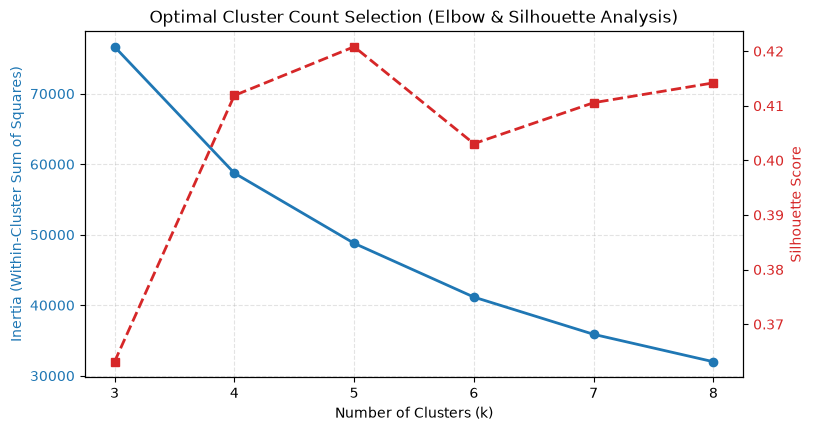

نمودار انتخاب k ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\figures\phase2\clustering_k_selection.png


In [3]:
print("در حال ارزیابی تعداد خوشه‌ها برای k از ۳ تا ۸...")
k_range = range(3, 9)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_umap_clustering)
    
    inertias.append(km.inertia_)
    sil = silhouette_score(X_umap_clustering, labels, sample_size=5000, random_state=42)
    silhouette_scores.append(sil)
    print(f"k = {k} | Silhouette Score: {sil:.4f} | Inertia: {km.inertia_:,.1f}")

# رسم نمودار ترکیبی Elbow و Silhouette
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))

color1 = "#1f77b4"
ax1.set_xlabel("Number of Clusters (k)", fontsize=10)
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)", color=color1, fontsize=10)
ax1.plot(k_range, inertias, marker="o", color=color1, linewidth=2, label="Inertia (Elbow)")
ax1.tick_params(axis="y", labelcolor=color1)
ax1.grid(True, linestyle="--", alpha=0.35)

ax2 = ax1.twinx()
color2 = "#d62728"
ax2.set_ylabel("Silhouette Score", color=color2, fontsize=10)
ax2.plot(k_range, silhouette_scores, marker="s", color=color2, linewidth=2, linestyle="--", label="Silhouette")
ax2.tick_params(axis="y", labelcolor=color2)

plt.title("Optimal Cluster Count Selection (Elbow & Silhouette Analysis)", fontsize=12)
k_plot_path = figures_dir / "clustering_k_selection.png"
plt.savefig(k_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"نمودار انتخاب k ذخیره شد در: {k_plot_path}")



## ۳. اجرای خوشه‌بندی نهایی و استخراج کلمات کلیدی و جملات شاخص هر خوشه



In [4]:
# انتخاب تعداد خوشه بهینه (بر اساس بالاترین/پایدارترین نقطه Silhouette در بازه تفکیک‌پذیر ۵ تا ۷)
OPTIMAL_K = int(k_range[np.argmax(silhouette_scores)])
# در صورتی که k=3 خیلی کلی بود و کاندیدای بعدی مثل 6 تفکیک بهتری داشت، می‌توانید مقدار OPTIMAL_K را دستی تنظیم کنید
print(f"تعداد خوشه انتخابی بر اساس بیشینه Silhouette: k = {OPTIMAL_K}")

kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=15)
df_cluster["cluster_id"] = kmeans_final.fit_predict(X_umap_clustering)

# استخراج ۱۰ کلمه کلیدی برتر هر خوشه با استفاده از میانگین وزن‌های TF-IDF
print("\n" + "="*70)
print("تفسیر و کلمات کلیدی متمایز هر خوشه:")
print("="*70)

cluster_summaries = []
for cid in range(OPTIMAL_K):
    mask = (df_cluster["cluster_id"] == cid).values
    cluster_size = mask.sum()
    cluster_pct = (cluster_size / len(df_cluster)) * 100
    mean_rating = df_cluster.loc[mask, "rating"].mean()
    
    # میانگین امتیاز TF-IDF کلمات در این خوشه منهای میانگین کل برای یافتن کلمات متمایز
    cluster_tfidf_mean = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    global_tfidf_mean = np.asarray(X_tfidf.mean(axis=0)).ravel()
    distinctive_scores = cluster_tfidf_mean - (0.5 * global_tfidf_mean)
    
    top_indices = distinctive_scores.argsort()[::-1][:10]
    top_terms = ", ".join(feature_names[top_indices])
    
    sample_sents = df_cluster.loc[mask, "sentence_text"].head(3).tolist()
    
    print(f"\n[خوشه {cid}] تعداد: {cluster_size:,} ({cluster_pct:.1f}%) | میانگین امتیاز: {mean_rating:.2f}")
    print(f"  کلمات کلیدی شاخص: {top_terms}")
    print("  نمونه جملات:")
    for s in sample_sents:
        print(f"    - {s[:110]}...")
        
    cluster_summaries.append({
        "cluster_id": cid,
        "count": cluster_size,
        "percentage": round(cluster_pct, 2),
        "mean_rating": round(mean_rating, 3),
        "top_keywords": top_terms
    })

df_cluster_summary = pd.DataFrame(cluster_summaries)
display(df_cluster_summary)



تعداد خوشه انتخابی بر اساس بیشینه Silhouette: k = 5

تفسیر و کلمات کلیدی متمایز هر خوشه:

[خوشه 0] تعداد: 6,420 (32.1%) | میانگین امتیاز: 3.99
  کلمات کلیدی شاخص: car, rc, fast, truck, great, remote, motor, fit, control, durable
  نمونه جملات:
    - Nice for a little girl but did no come with stickers as described!...
    - We noticed after a few days it's not taking off from the ground as quickly as it was when first used, but it m...
    - His papap drove tractor trailers for a living....

[خوشه 1] تعداد: 4,712 (23.6%) | میانگین امتیاز: 3.83
  کلمات کلیدی شاخص: product, great, buy, price, good, works, quality, money, work, just
  نمونه جملات:
    - Just make sure your order is from the US or it will take forever....
    - great as expected...
    - The shipping was fast and this company cares for your satisfaction in the their product....

[خوشه 2] تعداد: 5,045 (25.2%) | میانگین امتیاز: 4.12
  کلمات کلیدی شاخص: drone, fly, br, flying, camera, flight, video, drones, easy, great
  نمون

,cluster_id,count,percentage,mean_rating,top_keywords
0,0,6420,32.10,3.990,"car, rc, fast, truck, great, remote, motor, fi..."
1,1,4712,23.56,3.828,"product, great, buy, price, good, works, quali..."
2,2,5045,25.22,4.118,"drone, fly, br, flying, camera, flight, video,..."
3,3,2008,10.04,3.846,"battery, batteries, charger, charge, charging,..."
4,4,1815,9.07,4.339,"loves, fun, gift, old, love, son, year, year o..."


## ۴. مصورسازی خوشه‌های کشف‌شده در فضای دو بعدی UMAP و تحلیل امتیازها



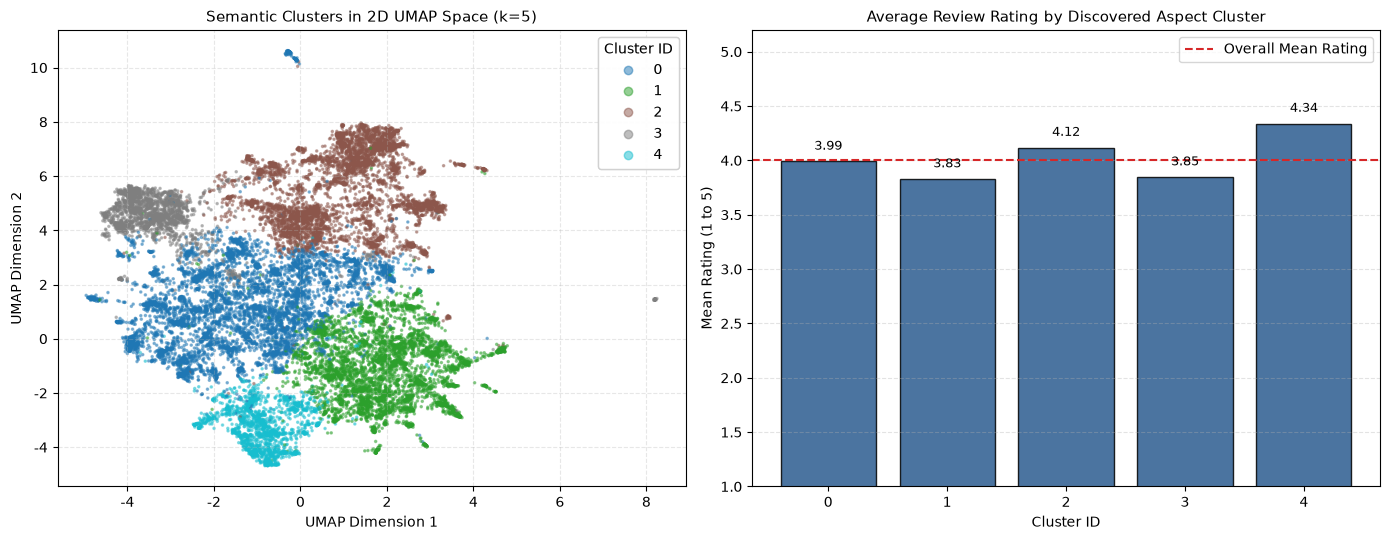

نمودار خوشه‌ها و ارتباط با امتیاز ذخیره شد در: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\figures\phase2\umap_clusters_and_ratings.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# نمودار سمت چپ: نقشه خوشه‌ها در فضای UMAP
scatter = axes[0].scatter(
    X_umap_2d[:, 0], X_umap_2d[:, 1],
    c=df_cluster["cluster_id"], cmap="tab10", s=2.5, alpha=0.45
)
axes[0].set_title(f"Semantic Clusters in 2D UMAP Space (k={OPTIMAL_K})", fontsize=11)
axes[0].set_xlabel("UMAP Dimension 1")
axes[0].set_ylabel("UMAP Dimension 2")
axes[0].grid(True, linestyle="--", alpha=0.3)
legend1 = axes[0].legend(*scatter.legend_elements(), title="Cluster ID", loc="best")
axes[0].add_artist(legend1)

# نمودار سمت راست: مقایسه میانگین امتیاز (Rating) در خوشه‌های مختلف (الزام مسیر ب)
bars = axes[1].bar(
    df_cluster_summary["cluster_id"].astype(str),
    df_cluster_summary["mean_rating"],
    color="#2b5c8f", alpha=0.85, edgecolor="black"
)
axes[1].axhline(df_cluster["rating"].mean(), color="#d62728", linestyle="--", linewidth=1.5, label="Overall Mean Rating")
axes[1].set_title("Average Review Rating by Discovered Aspect Cluster", fontsize=11)
axes[1].set_xlabel("Cluster ID")
axes[1].set_ylabel("Mean Rating (1 to 5)")
axes[1].set_ylim(1, 5.2)
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend()

for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.08, f"{yval:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
cluster_vis_path = figures_dir / "umap_clusters_and_ratings.png"
plt.savefig(cluster_vis_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"نمودار خوشه‌ها و ارتباط با امتیاز ذخیره شد در: {cluster_vis_path}")



## ۵. ذخیره مدل‌های آموزش‌دیده و دیتافریم برچسب‌خورده جهت تسک‌های بعدی



In [6]:
# ذخیره مدل UMAP و KMeans در پوشه models/phase2 (با رعایت gitignore)
joblib.dump(reducer_clustering, models_dir / "umap_5d_reducer.joblib")
joblib.dump(kmeans_final, models_dir / f"kmeans_k{OPTIMAL_K}.joblib")

# ذخیره جدول جملات به همراه برچسب خوشه در data/interim
labeled_sentences_path = interim_dir / "train_sentences_clustered_20k.parquet"
df_cluster.to_parquet(labeled_sentences_path, engine="fastparquet", index=False)

# ذخیره خلاصه جدول خوشه‌ها در reports یا interim برای گزارش‌نویسی
summary_csv_path = interim_dir / "cluster_summary_table.csv"
df_cluster_summary.to_csv(summary_csv_path, index=False)

print("تمامی مدل‌ها و خروجی‌های خوشه‌بندی با موفقیت ذخیره شدند:")
print(f" - مدل خوشه‌بندی: {models_dir / f'kmeans_k{OPTIMAL_K}.joblib'}")
print(f" - دیتافریم برچسب‌خورده: {labeled_sentences_path}")
print(f" - جدول خلاصه جنبه‌ها: {summary_csv_path}")

تمامی مدل‌ها و خروجی‌های خوشه‌بندی با موفقیت ذخیره شدند:
 - مدل خوشه‌بندی: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\models\phase2\kmeans_k5.joblib
 - دیتافریم برچسب‌خورده: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\interim\train_sentences_clustered_20k.parquet
 - جدول خلاصه جنبه‌ها: d:\University\Semaster-7\Data Analysis\Project\DataAnalysis-Project-Fall2026\data\interim\cluster_summary_table.csv
